(581, 17) 1978-01-01 2026-06-01
max |rebuilt - UMCSENT|: 0.1


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 33 seconds.



===== Sentiment (ICS) =====
                       mean     sd  r_hat
beta[unemployment]   -5.371  0.394    1.0
beta[jobs_yoy]       -0.818  0.728    1.0
beta[inflation_yoy]  -4.061  0.557    1.0
beta[real_wages_yoy]  1.160  0.603    1.0
beta[gdp_yoy]         5.511  0.623    1.0
sigma                 7.771  0.243    1.0
Sentiment (ICS)        gap  -29.2 [ -30.2, -28.2]   = -2.33 training SDs   coverage 2022+ 0/53


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


... (27 outputs left out)

Expected 35-54         gap  -22.1 [ -23.3, -20.9]   = -1.59 training SDs   coverage 2022+ 17/53


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


Expected 55plus        gap  -16.6 [ -17.8, -15.5]   = -1.38 training SDs   coverage 2022+ 21/53


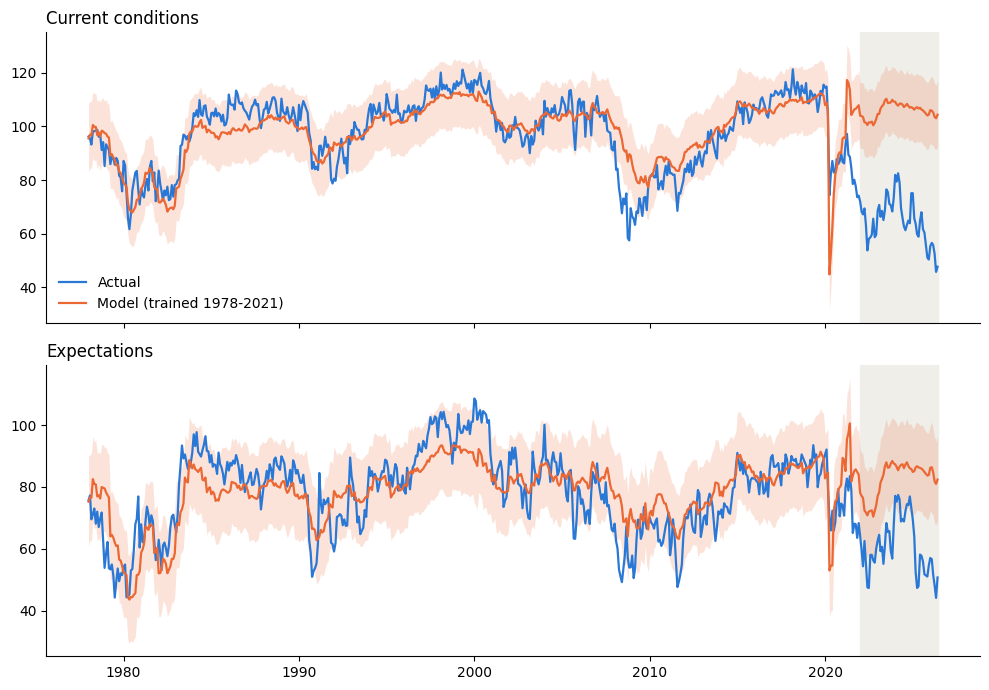

In [3]:
# %% Cell 1 -- load Michigan components + your predictors
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

PREDICTORS = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']
SPLIT = '2022'


def read_umich(path, names):
    """Michigan 'Historical' Excel tables: month name, year, then the numbers."""
    x = pd.read_excel(path, header=None).iloc[7:]
    x = x[x[1].notna()]
    dates = pd.to_datetime(x[0].str.strip() + ' ' + x[1].astype(int).astype(str), format='%B %Y')
    out = x.iloc[:, 2:2 + len(names)].apply(pd.to_numeric, errors='coerce')
    out.columns = names
    out.index = dates
    return out


comp = read_umich('redbk01b.xls', ['current', 'pf_now', 'durables',
                                   'expected', 'pf_next', 'bus_1yr', 'bus_5yr'])
age = read_umich('redbk03n.xls', ['ics_18_34', 'ics_35_54', 'ics_55plus',
                                  'cur_18_34', 'cur_35_54', 'cur_55plus',
                                  'exp_18_34', 'exp_35_54', 'exp_55plus'])

d = pd.read_csv('extended_monthly.csv', index_col=0, parse_dates=True)
d = d.join(comp[['current', 'expected']]).join(age)
d = d.loc['1978':, ['sentiment', 'current', 'expected'] + list(age.columns) + PREDICTORS]
d = d.dropna(subset=['sentiment', 'current', 'expected'] + PREDICTORS)
print(d.shape, d.index.min().date(), d.index.max().date())

# Michigan's own formula: sentiment is a fixed weighted mix of the two halves
#   ICS - 2 = 0.391 * (ICC - 2) + 0.609 * (ICE - 2)
check = 2 + (2.6424 * (d.current - 2) + 4.1134 * (d.expected - 2)) / 6.7558
print('max |rebuilt - UMCSENT|:', round((check - d.sentiment).abs().max(), 2))

is_train = d.index < SPLIT
is_test = ~is_train
X = d[PREDICTORS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values   # TRAINING mean/sd only


# %% Cell 2 -- same baseline model as before, for any outcome column
def fit_gap(col, label=None, quiet=False):
    keep = d[col].notna().values
    y = d[col].values
    with pm.Model(coords={'predictor': PREDICTORS}):
        alpha = pm.Normal('alpha', mu=85, sigma=20)
        beta = pm.Normal('beta', mu=0, sigma=5, dims='predictor')
        sigma = pm.HalfNormal('sigma', sigma=10)
        tr = is_train & keep
        pm.Normal('y', mu=alpha + pm.math.dot(Z[tr], beta), sigma=sigma, observed=y[tr])
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)

    a = idata.posterior['alpha'].values.reshape(-1)
    b = idata.posterior['beta'].values.reshape(-1, len(PREDICTORS))
    s = idata.posterior['sigma'].values.reshape(-1)
    mu_draws = a[:, None] + b @ Z.T
    rng = np.random.default_rng(1)
    pred = mu_draws + rng.normal(0, s[:, None], mu_draws.shape)
    lo, hi = np.percentile(pred, [5.5, 94.5], axis=0)

    te = is_test & keep
    gap_draws = (y[te] - mu_draws[:, te]).mean(axis=1)
    sd_train = y[is_train & keep].std()
    if not quiet:
        print(f'\n===== {label or col} =====')
        print(az.summary(idata, var_names=['beta', 'sigma'])[['mean', 'sd', 'r_hat']])
    inside = (y[te] >= lo[te]) & (y[te] <= hi[te])
    print(f'{label or col:22s} gap {gap_draws.mean():+6.1f} '
          f'[{np.percentile(gap_draws, 5.5):+6.1f},{np.percentile(gap_draws, 94.5):+6.1f}]   '
          f'= {gap_draws.mean() / sd_train:+.2f} training SDs   '
          f'coverage 2022+ {inside.sum()}/{te.sum()}')
    return gap_draws, mu_draws.mean(axis=0), lo, hi


# %% Cell 3 -- the overall index and its two halves
g_ics, mu_ics, lo_ics, hi_ics = fit_gap('sentiment', 'Sentiment (ICS)')
g_cur, mu_cur, lo_cur, hi_cur = fit_gap('current', 'Current conditions (ICC)')
g_exp, mu_exp, lo_exp, hi_exp = fit_gap('expected', 'Expectations (ICE)')

# how much of the sentiment gap comes from each half (Michigan's weights)
from_cur = 0.391 * g_cur.mean()
from_exp = 0.609 * g_exp.mean()
print(f'\nSentiment gap {g_ics.mean():+.1f}  =  current {from_cur:+.1f} '
      f'({100 * from_cur / (from_cur + from_exp):.0f}%)  +  expectations {from_exp:+.1f} '
      f'({100 * from_exp / (from_cur + from_exp):.0f}%)')


# %% Cell 4 -- plot the two halves
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, col, mu, lo, hi, title in [
        (axes[0], 'current', mu_cur, lo_cur, hi_cur, 'Current conditions'),
        (axes[1], 'expected', mu_exp, lo_exp, hi_exp, 'Expectations')]:
    ax.axvspan(pd.Timestamp(SPLIT), d.index.max(), color='#efeee9', zorder=0)
    ax.fill_between(d.index, lo, hi, color='#eb6834', alpha=0.18, lw=0)
    ax.plot(d.index, d[col], color='#2a78d6', lw=1.6, label='Actual')
    ax.plot(d.index, mu, color='#eb6834', lw=1.6, label='Model (trained 1978-2021)')
    ax.set_title(title, loc='left')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig('components_plot.png', dpi=200)


# %% Cell 5 -- by age: is the gap bigger for the young, and in which half?
print('\nGap by age group (index points; training SDs in the middle column)')
for part, prefix in [('Sentiment', 'ics'), ('Current', 'cur'), ('Expected', 'exp')]:
    for grp in ['18_34', '35_54', '55plus']:
        fit_gap(f'{prefix}_{grp}', f'{part} {grp.replace("_", "-")}', quiet=True)

In [4]:
# %% Cell 6 -- load income, education, region
inc = read_umich('redbk02n.xls', [f'{p}_{g}' for p in ['ics', 'cur', 'exp'] for g in ['bottom', 'middle', 'top']])
edu = read_umich('redbk04n.xls', [f'{p}_{g}' for p in ['ics', 'cur', 'exp'] for g in ['hs', 'somecol', 'college']])
reg = read_umich('redbk05a.xls', [f'{p}_{g}' for p in ['ics', 'cur', 'exp'] for g in ['ne', 'nc', 's', 'w']])
for t in [inc, edu, reg]:
    d = d.join(t)

In [5]:
# %% Cell 7 -- gap by income, education, region
for name, groups in [('income', ['bottom', 'middle', 'top']),
                     ('education', ['hs', 'somecol', 'college']),
                     ('region', ['ne', 'nc', 's', 'w'])]:
    print(f'\n--- {name} ---')
    for part, prefix in [('Current', 'cur'), ('Expected', 'exp')]:
        for g in groups:
            fit_gap(f'{prefix}_{g}', f'{part} {g}', quiet=True)


--- income ---


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 33 seconds.


Current bottom         gap  -37.7 [ -38.8, -36.7]   = -2.91 training SDs   coverage 2022+ 0/53


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


... (51 outputs left out)

Expected s             gap  -22.5 [ -23.7, -21.3]   = -1.70 training SDs   coverage 2022+ 12/53


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


Expected w             gap  -24.6 [ -25.9, -23.3]   = -1.82 training SDs   coverage 2022+ 11/53


      inflation_yoy  w_prices  b_prices
date                                   
1980           13.5      41.1      23.6
1983            3.2      18.4      15.7
1990            5.4      16.8      10.0
2000            3.4       7.8       3.8
2010            1.6      16.8       5.0
2019            1.8       7.3      11.2
2021            4.7      14.2      23.8
2022            8.0      39.8      42.4
2023            4.1      39.2      33.8
2024            3.0      40.3      32.8
2025            2.8      40.5      29.9
2026            3.5      50.2      37.8
Worse off: higher prices       corr 1978-2021 0.73   2022+ actual 41.1%  predicted from inflation 18.3%  excess +22.9
Bad time to buy: prices high   corr 1978-2021 0.73   2022+ actual 35.2%  predicted from inflation 10.3%  excess +24.9
date
1980-06-01    36.4
1983-06-01    20.5
2019-06-01     6.2
2022-06-01    15.6
2024-06-01    15.7
2026-06-01     9.6
Name: price_3yr, dtype: float64


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...


SamplingError: Initial evaluation of model at starting point failed!
Starting values:
{'alpha': array(84.89586699), 'beta': array([ 0.48793527,  0.79931862, -0.06872104, -0.91706124, -0.69608324,
       -0.71083066]), 'sigma_log__': array(1.71558115)}

Logp initial evaluation results:
{'alpha': -3.91, 'beta': -15.22, 'sigma': -0.97, 'y': nan}
You can call `model.debug()` for more details.

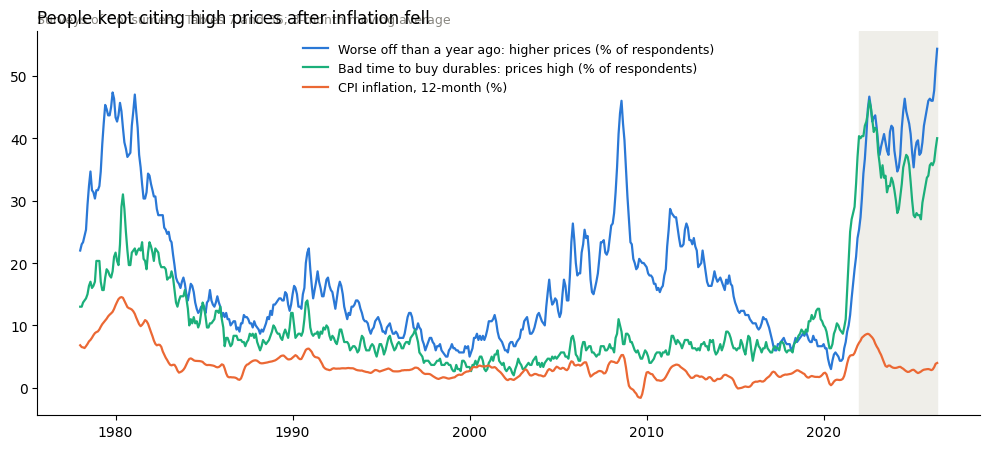

In [7]:
# Run these AFTER Cells 1-5 of components_model.py (they reuse d, read_umich, fit_gap).
# Needs redbk07.xls and redbk36.xls in the same folder.

# %% Cell 8 -- people's own reasons: "worse off because of higher prices", "bad time to buy, prices high"
t7 = read_umich('redbk07.xls', ['b_income', 'b_assets', 'b_debt',
                                'w_income', 'w_prices', 'w_assets', 'w_debt'])
t36 = read_umich('redbk36.xls', ['g_low_prices', 'g_prices_rising', 'g_low_rates', 'g_beat_rates',
                                 'g_prosperity', 'g_supply', 'b_prices', 'b_rates', 'b_afford',
                                 'b_uncertain', 'b_supply'])
d = d.join(t7[['w_prices']]).join(t36[['b_prices']])

# yearly averages, side by side with inflation
yearly = d[['inflation_yoy', 'w_prices', 'b_prices']].groupby(d.index.year).mean().round(1)
print(yearly.loc[[1980, 1983, 1990, 2000, 2010, 2019, 2021, 2022, 2023, 2024, 2025, 2026]])

# same idea as the main model: fit share-citing-prices on inflation 1978-2021, compare 2022+
for col, label in [('w_prices', 'Worse off: higher prices'), ('b_prices', 'Bad time to buy: prices high')]:
    ok = d[col].notna()
    tr = is_train & ok
    slope, intercept = np.polyfit(d.inflation_yoy[tr], d[col][tr], 1)
    predicted = intercept + slope * d.inflation_yoy
    te = is_test & ok
    print(f'{label:30s} corr 1978-2021 {d[col][tr].corr(d.inflation_yoy[tr]):.2f}   '
          f'2022+ actual {d[col][te].mean():.1f}%  predicted from inflation {predicted[te].mean():.1f}%  '
          f'excess {d[col][te].mean() - predicted[te].mean():+.1f}')


# %% Cell 9 -- the chart for the paper
fig, ax = plt.subplots(figsize=(10, 4.6))
smooth = d[['inflation_yoy', 'w_prices', 'b_prices']].rolling(3, min_periods=1).mean()
ax.plot(d.index, smooth.w_prices, color='#2a78d6', lw=1.6, label='Worse off than a year ago: higher prices (% of respondents)')
ax.plot(d.index, smooth.b_prices, color='#1baf7a', lw=1.6, label='Bad time to buy durables: prices high (% of respondents)')
ax.plot(d.index, smooth.inflation_yoy, color='#eb6834', lw=1.6, label='CPI inflation, 12-month (%)')
ax.axvspan(pd.Timestamp(SPLIT), d.index.max(), color='#efeee9', zorder=0)
ax.set_title('People kept citing high prices after inflation fell', loc='left')
ax.text(0, 1.015, 'Surveys of Consumers, Tables 7 and 36; 3-month moving average',
        transform=ax.transAxes, color='#898781', fontsize=9, va='bottom')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper center', fontsize=9)
fig.tight_layout()
fig.savefig('price_complaints.png', dpi=200)


# %% Cell 10 -- add a PRICE LEVEL variable: how much higher prices are than 3 years ago
# Built from inflation_yoy you already have: chain the last three 12-month changes.
#   price_3yr = (1 + this year) * (1 + last year) * (1 + the year before) - 1
i = d['inflation_yoy'] / 100
d['price_3yr'] = ((1 + i) * (1 + i.shift(12)) * (1 + i.shift(24)) - 1) * 100
print(d['price_3yr'].loc[['1980-06-01', '1983-06-01', '2019-06-01', '2022-06-01', '2024-06-01', '2026-06-01']].round(1))

BASE = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']

# swap in the new predictor list (fit_gap reads PREDICTORS and Z)
PREDICTORS = BASE + ['price_3yr']
X = d[PREDICTORS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values      # training mean/sd only

g_ics_p, mu_ics_p, lo_ics_p, hi_ics_p = fit_gap('sentiment', 'Sentiment + price level')
g_cur_p, mu_cur_p, lo_cur_p, hi_cur_p = fit_gap('current', 'Current + price level')
g_exp_p, mu_exp_p, lo_exp_p, hi_exp_p = fit_gap('expected', 'Expected + price level')

print('\nGap 2022+         without price level   with price level')
for label, before, after in [('Sentiment', g_ics, g_ics_p), ('Current', g_cur, g_cur_p),
                             ('Expected', g_exp, g_exp_p)]:
    print(f'{label:12s}      {before.mean():+6.1f}               {after.mean():+6.1f}')


# %% Cell 11 -- plot current conditions with the price-level model
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axvspan(pd.Timestamp(SPLIT), d.index.max(), color='#efeee9', zorder=0)
ax.fill_between(d.index, lo_cur_p, hi_cur_p, color='#eb6834', alpha=0.18, lw=0)
ax.plot(d.index, d.current, color='#2a78d6', lw=1.6, label='Actual')
ax.plot(d.index, mu_cur, color='#898781', lw=1.2, ls='--', label='Baseline model')
ax.plot(d.index, mu_cur_p, color='#eb6834', lw=1.6, label='Baseline + price level')
ax.set_title('Current conditions: does the price level close the gap?', loc='left')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig('current_price_level.png', dpi=200)

# put things back so earlier cells still work if you rerun them
PREDICTORS = BASE
X = d[PREDICTORS]
Z = ((X - X[is_train].mean()) / X[is_train].std()).values

Correlation with sentiment       1978-2021   2022+
gas_price  vs sentiment         -0.26      -0.36
gas_price  vs current           -0.25      -0.24
gas_price  vs expected          -0.25      -0.39
real_gas   vs sentiment         -0.58      -0.25
real_gas   vs current           -0.56      -0.10
real_gas   vs expected          -0.56      -0.31


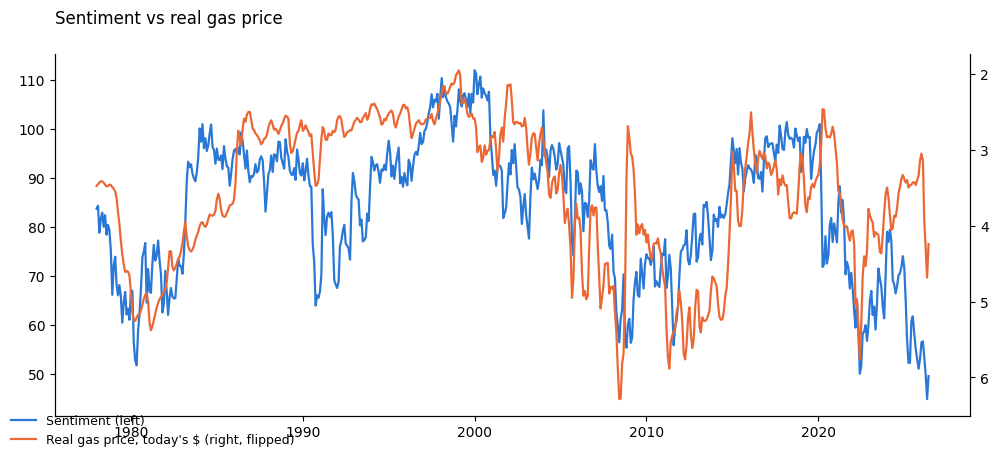

In [8]:
# %% Gas price vs sentiment
from pandas_datareader import data as web

gas = web.DataReader(['APU000074714', 'CPIAUCSL'], 'fred', '1978-01-01')
gas = gas.rename(columns={'APU000074714': 'gas_price'})
gas['real_gas'] = gas.gas_price / gas.CPIAUCSL * gas.CPIAUCSL.dropna().iloc[-1]   # today's dollars

g = d[['sentiment', 'current', 'expected']].join(gas[['gas_price', 'real_gas']]).dropna()
pre, post = g.index < '2022', g.index >= '2022'

print('Correlation with sentiment       1978-2021   2022+')
for col in ['gas_price', 'real_gas']:
    for s in ['sentiment', 'current', 'expected']:
        print(f'{col:10s} vs {s:10s}        {g[col][pre].corr(g[s][pre]):+.2f}      {g[col][post].corr(g[s][post]):+.2f}')

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(g.index, g.sentiment, color='#2a78d6', lw=1.6, label='Sentiment (left)')
ax2 = ax.twinx()
ax2.plot(g.index, g.real_gas, color='#eb6834', lw=1.6, label='Real gas price, today\'s $ (right, flipped)')
ax2.invert_yaxis()                        # flipped: higher gas = lower on the chart
ax.set_title('Sentiment vs real gas price', loc='left', pad=22)
fig.legend(frameon=False, loc='lower left', fontsize=9)
ax.spines[['top']].set_visible(False); ax2.spines[['top']].set_visible(False)
fig.tight_layout()
fig.savefig('gas_vs_sentiment.png', dpi=200)

/var/folders/xg/2jx4h1913bx28fptfgb7xjx00000gn/T/ipykernel_23408/1450181637.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  out[c + '_yoy'] = p[c].pct_change(12) * 100
/var/folders/xg/2jx4h1913bx28fptfgb7xjx00000gn/T/ipykernel_23408/1450181637.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  out[c + '_yoy'] = p[c].pct_change(12) * 100
/var/folders/xg/2jx4h1913bx28fptfgb7xjx00000gn/T/ipykernel_23408/1450181637.py:16: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to ca

Correlation with sentiment          1978-2021   2022+
all_goods_vs_wage                    -0.05      +0.07
all_goods_yoy                        -0.41      -0.36
groceries_vs_wage                    -0.09      +0.19
groceries_yoy                        -0.36      -0.30
durables_vs_wage                     +0.04      +0.12
durables_yoy                         -0.42      -0.27
services_vs_wage                     +0.36      +0.30
services_yoy                         -0.39      +0.23

Affordability (2019 = 100; above 100 = takes more work hours than in 2019)
      all_goods_vs_wage  groceries_vs_wage  durables_vs_wage  services_vs_wage
date                                                                          
2017              104.3              105.2             107.1             101.0
2018              103.2              102.6             103.2             100.8
2019              100.0              100.0             100.0             100.0
2020               95.0               98.6 

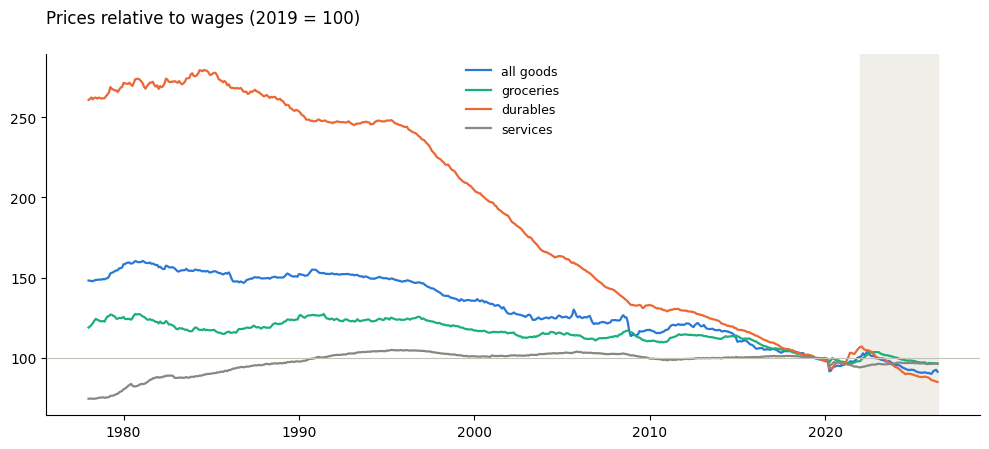

In [9]:
# %% Goods prices vs sentiment
from pandas_datareader import data as web

codes = {'CUSR0000SAC': 'all_goods',      # all commodities (goods)
         'CUSR0000SAF11': 'groceries',    # food at home
         'CUSR0000SAD': 'durables',       # cars, appliances, furniture
         'CUSR0000SAS': 'services',       # for comparison: not goods
         'AHETPI': 'wage'}                # avg hourly earnings, production workers
p = web.DataReader(list(codes), 'fred', '1977-01-01').rename(columns=codes)

cats = ['all_goods', 'groceries', 'durables', 'services']
out = pd.DataFrame(index=p.index)
for c in cats:
    out[c + '_vs_wage'] = p[c] / p.wage                 # hours of work to buy the basket
    out[c + '_vs_wage'] /= out[c + '_vs_wage']['2019'].mean() / 100   # 2019 = 100
    out[c + '_yoy'] = p[c].pct_change(12) * 100

g = d[['sentiment', 'current', 'expected']].join(out).dropna()
pre, post = g.index < '2022', g.index >= '2022'

print('Correlation with sentiment          1978-2021   2022+')
for c in cats:
    for kind in ['_vs_wage', '_yoy']:
        col = c + kind
        print(f'{col:22s}               {g[col][pre].corr(g.sentiment[pre]):+.2f}      '
              f'{g[col][post].corr(g.sentiment[post]):+.2f}')

print('\nAffordability (2019 = 100; above 100 = takes more work hours than in 2019)')
print(g[[c + '_vs_wage' for c in cats]].groupby(g.index.year).mean().loc[2017:].round(1))

fig, ax = plt.subplots(figsize=(10, 4.6))
for c, color in zip(cats, ['#2a78d6', '#1baf7a', '#eb6834', '#898781']):
    ax.plot(g.index, g[c + '_vs_wage'], lw=1.6, color=color, label=c.replace('_', ' '))
ax.axhline(100, color='#c3c2b7', lw=0.8)
ax.axvspan(pd.Timestamp('2022'), g.index.max(), color='#efeee9', zorder=0)
ax.set_title('Prices relative to wages (2019 = 100)', loc='left', pad=22)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig('goods_vs_wages.png', dpi=200)

In [11]:
print(pd.read_csv('extended_monthly.csv', index_col=0).columns.tolist())

['sentiment', 'unemployment', 'jobs_yoy', 'inflation_yoy', 'wages_yoy', 'real_wages_yoy', 'gdp_yoy', 'mortgage_rates_monthly', 'food_prices_yoy', 'rent_prices_yoy', 'gas_prices_yoy', 'house_prices_yoy', 'rdpi_yoy', 'savings', 'credit_yoy', 'revolving_ratio']


In [12]:
HOUSEHOLD = ['mortgage_rates_monthly', 'food_prices_yoy', 'rent_prices_yoy', 'gas_prices_yoy',
             'house_prices_yoy', 'rdpi_yoy', 'savings', 'revolving_ratio']

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, z, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 42 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details



===== Headline baseline (shrinkage) (5 predictors, 504 training months) =====
R2 train 0.630   RMSE train 7.53   RMSE test 31.49
GAP 2022+ -30.7 [-31.8, -29.6]   coverage 2022+ 0/53
by year: 2022 -29.3  2023 -30.1  2024 -23.2  2025 -36.0  2026 -40.1
                beta    lo    hi clear
gdp_yoy         5.32  4.33  6.34   yes
unemployment   -5.13 -5.78 -4.48   yes
real_wages_yoy  3.01  1.96  4.08   yes
inflation_yoy  -1.45 -2.42 -0.48   yes
jobs_yoy        0.46 -0.71  1.65      
r_hat max 1.000   divergences 0


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, z, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 45 seconds.



===== Baseline + household (13 predictors, 504 training months) =====
R2 train 0.766   RMSE train 5.99   RMSE test 27.69
GAP 2022+ -26.5 [-27.9, -25.2]   coverage 2022+ 2/53
by year: 2022 -18.0  2023 -28.4  2024 -22.7  2025 -32.9  2026 -35.9
                        beta     lo    hi clear
inflation_yoy          -8.75 -10.34 -7.09   yes
unemployment           -6.63  -7.42 -5.84   yes
mortgage_rates_monthly  5.93   5.02  6.81   yes
gdp_yoy                 2.69   1.69  3.67   yes
savings                 2.15   0.95  3.31   yes
house_prices_yoy        1.89   1.28  2.50   yes
revolving_ratio         1.37   0.21  2.54   yes
gas_prices_yoy          1.19   0.27  2.11   yes
rent_prices_yoy         0.99  -0.04  2.03      
rdpi_yoy                0.82   0.12  1.51   yes
jobs_yoy                0.79  -0.30  1.87      
food_prices_yoy        -0.70  -1.29 -0.10   yes
real_wages_yoy          0.07  -0.95  1.10      
r_hat max 1.000   divergences 0


... (5 outputs left out)


===== Best economic model -> CURRENT conditions (17 predictors, 504 training months) =====
R2 train 0.815   RMSE train 5.77   RMSE test 34.51
GAP 2022+ -33.5 [-35.5, -31.4]   coverage 2022+ 1/53
by year: 2022 -25.5  2023 -34.2  2024 -31.1  2025 -37.6  2026 -44.9
                        beta    lo    hi clear
unemployment           -6.83 -7.82 -5.83   yes
price_3yr              -4.95 -6.76 -3.15   yes
inflation_yoy          -4.80 -6.86 -2.76   yes
groceries_vs_wage       3.78  2.04  5.56   yes
rent_prices_yoy         3.22  1.95  4.46   yes
mortgage_rates_monthly  2.91  1.07  4.81   yes
revolving_ratio        -2.77 -4.03 -1.50   yes
gas_prices_yoy          2.03  0.98  3.11   yes
food_prices_yoy        -1.99 -2.61 -1.35   yes
rdpi_yoy                1.81  1.08  2.53   yes
real_gas               -1.59 -2.50 -0.65   yes
house_prices_yoy        1.50  0.84  2.17   yes
goods_vs_wage          -1.31 -3.65  0.88      
gdp_yoy                 1.26  0.24  2.29   yes
jobs_yoy                0.98 -0

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, tau, z, sigma]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 48 seconds.



===== Best economic model -> EXPECTATIONS (17 predictors, 504 training months) =====
R2 train 0.744   RMSE train 6.31   RMSE test 18.32
GAP 2022+ -16.2 [-18.5, -13.9]   coverage 2022+ 18/53
by year: 2022 -9.3  2023 -23.6  2024 -7.8  2025 -21.7  2026 -22.0
                        beta    lo    hi clear
rent_prices_yoy         5.49  4.17  6.87   yes
gdp_yoy                 5.00  3.85  6.09   yes
groceries_vs_wage       4.10  2.06  6.11   yes
inflation_yoy          -4.07 -6.30 -1.77   yes
real_wages_yoy          3.92  2.69  5.19   yes
price_3yr              -3.92 -5.85 -1.95   yes
mortgage_rates_monthly  3.30  1.25  5.42   yes
gas_prices_yoy          3.19  2.03  4.38   yes
real_gas               -2.86 -3.87 -1.84   yes
goods_vs_wage          -2.66 -5.25 -0.13   yes
unemployment           -2.38 -3.46 -1.26   yes
rdpi_yoy                1.08  0.26  1.89   yes
food_prices_yoy        -1.04 -1.73 -0.37   yes
house_prices_yoy        0.90  0.21  1.59   yes
savings                 0.61 -0.73  2.

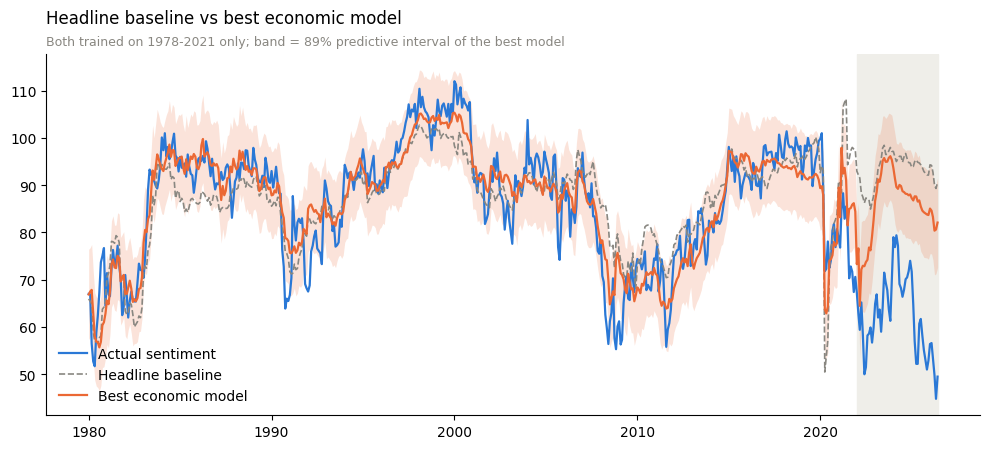

In [14]:
# Run AFTER Cells 1-5 of components_model.py and Cell 10 of price_level_cells.py (for price_3yr).
#
# "Best economic model": every OBJECTIVE economic measure we have, trained on 1978-2021 only.
# Rules that keep it honest:
#   - no opinion data on the right-hand side (no expectations, no price complaints) -> not circular
#   - no lagged sentiment -> that would "fit" by copying last month, explaining nothing
#   - variables picked on economic grounds BEFORE looking at the 2022+ result, never by test gap
# With ~17 correlated predictors, a plain model can overfit. So the slopes get a SHRINKAGE prior:
# they share one scale tau that the data estimates. Weak predictors get pulled toward zero.

# %% Cell 16 -- extra objective price measures from FRED
from pandas_datareader import data as web

fred = web.DataReader(['APU000074714', 'CPIAUCSL', 'CUSR0000SAF11', 'CUSR0000SAC', 'AHETPI'],
                      'fred', '1975-01-01')
extra = pd.DataFrame(index=fred.index)
extra['real_gas'] = fred.APU000074714 / fred.CPIAUCSL * fred.CPIAUCSL.dropna().iloc[-1]   # $/gal, today's dollars
extra['groceries_vs_wage'] = fred.CUSR0000SAF11 / fred.AHETPI       # work hours per grocery basket
extra['goods_vs_wage'] = fred.CUSR0000SAC / fred.AHETPI             # work hours per goods basket
BASE = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']
HOUSEHOLD = ['mortgage_rates_monthly', 'food_prices_yoy', 'rent_prices_yoy', 'gas_prices_yoy',
             'house_prices_yoy', 'rdpi_yoy', 'savings', 'revolving_ratio']

# Cell 1 kept only a few columns of extended_monthly.csv -- bring the household ones back
hh = pd.read_csv('extended_monthly.csv', index_col=0, parse_dates=True)[HOUSEHOLD]
new = pd.concat([hh, extra], axis=1)
d = d.drop(columns=[c for c in new.columns if c in d.columns]).join(new)
PRICE_LEVEL = ['price_3yr', 'real_gas', 'groceries_vs_wage', 'goods_vs_wage']
ALL = BASE + HOUSEHOLD + PRICE_LEVEL


# %% Cell 17 -- shrinkage model, works for any predictor list and outcome
def fit_shrink(cols, outcome='sentiment', label=''):
    s = d[[outcome] + cols].dropna()
    y = s[outcome].values
    tr = (s.index < SPLIT)
    te = ~tr
    X = s[cols]
    Z = ((X - X[tr].mean()) / X[tr].std()).values             # training mean/sd only

    with pm.Model(coords={'predictor': cols}):
        alpha = pm.Normal('alpha', mu=85, sigma=20)
        tau = pm.HalfNormal('tau', sigma=5)                    # how big slopes are allowed to be
        z = pm.Normal('z', 0, 1, dims='predictor')
        beta = pm.Deterministic('beta', tau * z, dims='predictor')   # non-centered: samples cleanly
        sigma = pm.HalfNormal('sigma', sigma=10)
        pm.Normal('y', mu=alpha + pm.math.dot(Z[tr], beta), sigma=sigma, observed=y[tr])
        idata = pm.sample(1000, tune=1500, chains=4, target_accept=0.95, random_seed=1)

    a = idata.posterior['alpha'].values.reshape(-1)
    b = idata.posterior['beta'].values.reshape(-1, len(cols))
    sg = idata.posterior['sigma'].values.reshape(-1)
    mu_draws = a[:, None] + b @ Z.T
    rng = np.random.default_rng(1)
    pred = mu_draws + rng.normal(0, sg[:, None], mu_draws.shape)
    lo, hi = np.percentile(pred, [5.5, 94.5], axis=0)
    mu = mu_draws.mean(axis=0)
    gap = (y[te] - mu_draws[:, te]).mean(axis=1)
    resid = y - mu
    inside = (y[te] >= lo[te]) & (y[te] <= hi[te])

    print(f'\n===== {label} ({len(cols)} predictors, {tr.sum()} training months) =====')
    print(f'R2 train {1 - resid[tr].var() / y[tr].var():.3f}   RMSE train {np.sqrt((resid[tr] ** 2).mean()):.2f}   '
          f'RMSE test {np.sqrt((resid[te] ** 2).mean()):.2f}')
    print(f'GAP 2022+ {gap.mean():+.1f} [{np.percentile(gap, 5.5):+.1f}, {np.percentile(gap, 94.5):+.1f}]   '
          f'coverage 2022+ {inside.sum()}/{te.sum()}')
    by_year = pd.Series(resid[te], index=s.index[te]).groupby(lambda t: t.year).mean()
    print('by year: ' + '  '.join(f'{yr} {v:+.1f}' for yr, v in by_year.items()))

    # slopes, biggest first, with whether the 89% interval excludes zero
    lo_b, hi_b = np.percentile(b, [5.5, 94.5], axis=0)
    tab = pd.DataFrame({'beta': b.mean(0), 'lo': lo_b, 'hi': hi_b}, index=cols)
    tab['clear'] = np.where((tab.lo > 0) | (tab.hi < 0), 'yes', '')
    print(tab.reindex(tab.beta.abs().sort_values(ascending=False).index).round(2))
    print(f"r_hat max {float(az.summary(idata, var_names=['beta'])['r_hat'].max()):.3f}   "
          f"divergences {int(idata.sample_stats.diverging.values.sum())}")
    return s.index, y, mu, lo, hi


# %% Cell 18 -- three models on the SAME months, so the gaps are comparable
common = d[['sentiment', 'current', 'expected'] + ALL].dropna().index
d_full = d
d = d.loc[common]

r_base = fit_shrink(BASE, 'sentiment', 'Headline baseline (shrinkage)')
r_hh = fit_shrink(BASE + HOUSEHOLD, 'sentiment', 'Baseline + household')
r_all = fit_shrink(ALL, 'sentiment', 'Best economic model')

# the half where the gap lives
r_cur = fit_shrink(ALL, 'current', 'Best economic model -> CURRENT conditions')
r_exp = fit_shrink(ALL, 'expected', 'Best economic model -> EXPECTATIONS')

d = d_full


# %% Cell 19 -- plot baseline vs best economic model
idx, y, mu_b, _, _ = r_base
_, _, mu_a, lo_a, hi_a = r_all
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axvspan(pd.Timestamp(SPLIT), idx.max(), color='#efeee9', zorder=0)
ax.fill_between(idx, lo_a, hi_a, color='#eb6834', alpha=0.18, lw=0)
ax.plot(idx, y, color='#2a78d6', lw=1.6, label='Actual sentiment')
ax.plot(idx, mu_b, color='#898781', lw=1.2, ls='--', label='Headline baseline')
ax.plot(idx, mu_a, color='#eb6834', lw=1.6, label='Best economic model')
ax.set_title('Headline baseline vs best economic model', loc='left', pad=22)
ax.text(0, 1.015, 'Both trained on 1978-2021 only; band = 89% predictive interval of the best model',
        transform=ax.transAxes, color='#898781', fontsize=9, va='bottom')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig('best_economic_model.png', dpi=200)

In [17]:
def read_table(path, positions, names):
    """Michigan Historical Excel: column 0 = month, 1 = year, numbers after that."""
    x = pd.read_excel(path, header=None)
    x = x[pd.to_numeric(x[1], errors='coerce').notna()]
    dates = pd.to_datetime(x[0].str.strip() + ' ' + x[1].astype(int).astype(str), format='%B %Y')
    out = x.iloc[:, positions].apply(pd.to_numeric, errors='coerce')
    out.columns = names
    out.index = dates
    return out

In [19]:
# load the two perception measures if they aren't already in d
if 'prices_beat_income' not in d.columns:
    t14 = read_table('redbk14.xls', [2, 4], ['income_beats_prices', 'prices_beat_income'])
    d = d.join(t14)
if 'w_prices' not in d.columns:
    t7 = read_umich('redbk07.xls', ['b_income', 'b_assets', 'b_debt',
                                    'w_income', 'w_prices', 'w_assets', 'w_debt'])
    d = d.join(t7[['w_prices']])

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, g, s_p, a_s, b, c, s_s]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 35 seconds.



===== MAIN: prices_beat_income -> sentiment  (528 training months) =====
c (effect of +1 SD perception, sentiment points)    -6.4 [  -6.9,   -6.0]
perception excess 2022+ (% of respondents)          +18.4 [ +17.7,  +19.2]
GAP 2022+ vs economy-only prediction               -29.2 [ -30.2,  -28.2]
   through excess perception                       -17.8 [ -19.2,  -16.3]
   remaining                                       -11.5 [ -12.9,  -10.1]
   share through perception                          61% [56%, 65%]
date       2022  2023  2024  2025  2026
through_P  -7.1 -10.4 -18.7 -29.3 -30.7
remaining -18.4 -18.0  -3.8  -6.2  -9.5
r_hat max 1.000   divergences 0


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, g, s_p, a_s, b, c, s_s]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 35 seconds.



===== CHECK: other perception measure: w_prices -> sentiment  (528 training months) =====
c (effect of +1 SD perception, sentiment points)    -8.6 [  -9.3,   -7.9]
perception excess 2022+ (% of respondents)          +25.9 [ +25.1,  +26.6]
GAP 2022+ vs economy-only prediction               -29.2 [ -30.2,  -28.2]
   through excess perception                       -22.7 [ -24.7,  -20.8]
   remaining                                        -6.5 [  -8.6,   -4.5]
   share through perception                          78% [71%, 84%]
date       2022  2023  2024  2025  2026
through_P -11.5 -21.9 -26.0 -26.2 -33.7
remaining -13.9  -6.5   3.5  -9.4  -6.6
r_hat max 1.000   divergences 0


Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, g, s_p, a_s, b, c, s_s]
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.
WARNING (pytensor.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 35 seconds.



===== CHECK: current conditions: prices_beat_income -> current  (528 training months) =====
c (effect of +1 SD perception, sentiment points)    -5.3 [  -5.8,   -4.8]
perception excess 2022+ (% of respondents)          +18.4 [ +17.7,  +19.2]
GAP 2022+ vs economy-only prediction               -40.9 [ -42.0,  -40.0]
   through excess perception                       -14.7 [ -16.3,  -13.2]
   remaining                                       -26.2 [ -27.8,  -24.6]
   share through perception                          36% [32%, 40%]
date       2022  2023  2024  2025  2026
through_P  -5.9  -8.6 -15.5 -24.2 -25.4
remaining -33.2 -29.2 -21.7 -20.0 -27.0
r_hat max 1.000   divergences 0


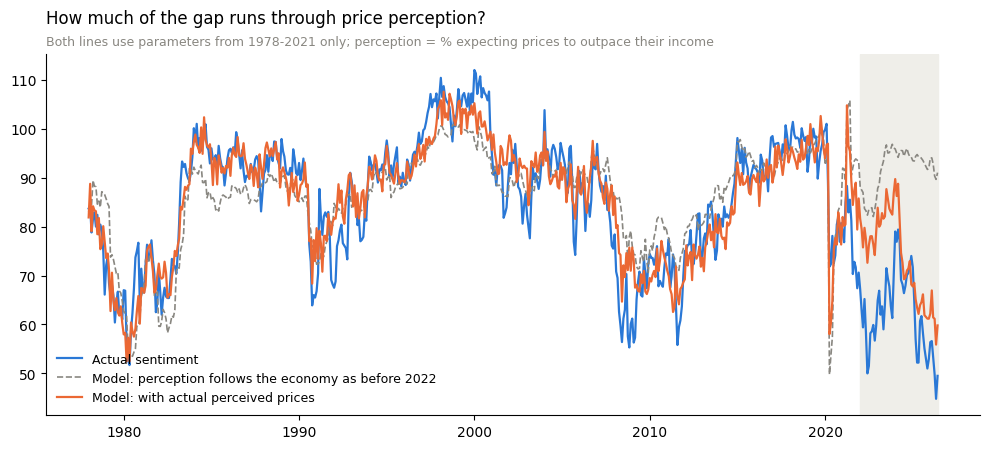

In [20]:
# Run AFTER Cells 1-5 (components_model.py), Cell 8 (price_level_cells.py, gives w_prices)
# and Cell 12 (drivers_cells.py, gives prices_beat_income).
#
# Two equations, fit together on 1978-2021:
#
#   perception[t] = a_p + X[t] . g + noise      how bad people say prices are, given the economy
#   sentiment[t]  = a_s + X[t] . b + c * perception[t] + noise
#
# X = the five headline indicators. Then for 2022+ we ask:
#   "If perception had followed its usual relationship with the economy, what would sentiment be?"
# and split the gap into
#   through_perception = c * (actual perception - perception the economy predicts)
#   remaining          = everything else
#
# Caveat for the write-up: perception and sentiment come from the same respondents, so part of
# the link is shared mood. This is an accounting of where the gap flows, not proof of cause.

# %% Cell 20 -- the model
BASE = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']


def fit_perception(perception, outcome='sentiment', label=''):
    s = d[[outcome, perception] + BASE].dropna()
    tr = (s.index < SPLIT)
    te = ~tr
    X = s[BASE]
    Z = ((X - X[tr].mean()) / X[tr].std()).values                     # training mean/sd only
    p_mean, p_sd = s[perception][tr].mean(), s[perception][tr].std()
    P = ((s[perception] - p_mean) / p_sd).values                       # perception in training SDs
    y = s[outcome].values

    with pm.Model(coords={'predictor': BASE}):
        # perception equation
        a_p = pm.Normal('a_p', 0, 1)
        g = pm.Normal('g', 0, 1, dims='predictor')
        s_p = pm.HalfNormal('s_p', 1)
        pm.Normal('P_obs', a_p + pm.math.dot(Z[tr], g), s_p, observed=P[tr])

        # sentiment equation
        a_s = pm.Normal('a_s', 85, 20)
        b = pm.Normal('b', 0, 5, dims='predictor')
        c = pm.Normal('c', 0, 5)                                      # sentiment points per 1 SD of perception
        s_s = pm.HalfNormal('s_s', 10)
        pm.Normal('y_obs', a_s + pm.math.dot(Z[tr], b) + c * P[tr], s_s, observed=y[tr])

        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1)

    post = idata.posterior
    a_p_ = post['a_p'].values.reshape(-1)
    g_ = post['g'].values.reshape(-1, len(BASE))
    a_s_ = post['a_s'].values.reshape(-1)
    b_ = post['b'].values.reshape(-1, len(BASE))
    c_ = post['c'].values.reshape(-1)

    P_hat = a_p_[:, None] + g_ @ Z.T                                   # perception the economy predicts
    with_actual_P = a_s_[:, None] + b_ @ Z.T + c_[:, None] * P[None, :]
    with_usual_P = a_s_[:, None] + b_ @ Z.T + c_[:, None] * P_hat      # counterfactual

    gap_total = (y[te] - with_usual_P[:, te]).mean(axis=1)
    through_P = (with_actual_P[:, te] - with_usual_P[:, te]).mean(axis=1)
    remaining = (y[te] - with_actual_P[:, te]).mean(axis=1)
    share = 100 * through_P / gap_total
    P_excess = (P[te] - P_hat[:, te]).mean(axis=1) * p_sd               # back in % of respondents

    def ci(x):
        return f'{x.mean():+6.1f} [{np.percentile(x, 5.5):+6.1f}, {np.percentile(x, 94.5):+6.1f}]'

    print(f'\n===== {label}: {perception} -> {outcome}  ({tr.sum()} training months) =====')
    print(f'c (effect of +1 SD perception, sentiment points)  {ci(c_)}')
    print(f'perception excess 2022+ (% of respondents)         {ci(P_excess)}')
    print(f'GAP 2022+ vs economy-only prediction              {ci(gap_total)}')
    print(f'   through excess perception                      {ci(through_P)}')
    print(f'   remaining                                      {ci(remaining)}')
    print(f'   share through perception                       {share.mean():5.0f}% '
          f'[{np.percentile(share, 5.5):.0f}%, {np.percentile(share, 94.5):.0f}%]')
    by_year = pd.DataFrame({'through_P': (with_actual_P - with_usual_P)[:, te].mean(0),
                            'remaining': y[te] - with_actual_P[:, te].mean(0)},
                           index=s.index[te]).groupby(lambda t: t.year).mean().round(1)
    print(by_year.T.to_string())
    print(f"r_hat max {float(az.summary(idata, var_names=['g', 'b', 'c'])['r_hat'].max()):.3f}   "
          f"divergences {int(idata.sample_stats.diverging.values.sum())}")
    return s.index, y, with_actual_P.mean(0), with_usual_P.mean(0)


# %% Cell 21 -- main result, plus two checks
r_main = fit_perception('prices_beat_income', 'sentiment', 'MAIN')
r_alt = fit_perception('w_prices', 'sentiment', 'CHECK: other perception measure')
r_cur = fit_perception('prices_beat_income', 'current', 'CHECK: current conditions')


# %% Cell 22 -- plot
idx, y, mu_actual_P, mu_usual_P = r_main
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axvspan(pd.Timestamp(SPLIT), idx.max(), color='#efeee9', zorder=0)
ax.plot(idx, y, color='#2a78d6', lw=1.6, label='Actual sentiment')
ax.plot(idx, mu_usual_P, color='#898781', lw=1.2, ls='--',
        label='Model: perception follows the economy as before 2022')
ax.plot(idx, mu_actual_P, color='#eb6834', lw=1.6, label='Model: with actual perceived prices')
ax.set_title('How much of the gap runs through price perception?', loc='left', pad=22)
ax.text(0, 1.015, 'Both lines use parameters from 1978-2021 only; perception = % expecting prices '
        'to outpace their income', transform=ax.transAxes, color='#898781', fontsize=9, va='bottom')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='lower left', fontsize=9)
fig.tight_layout()
fig.savefig('perception_model.png', dpi=200)

In [21]:
r_placebo1 = fit_perception('rates_will_rise', 'sentiment', 'PLACEBO: expect interest rates to rise')
r_placebo2 = fit_perception('news_bad_unemployment', 'sentiment', 'PLACEBO: heard bad unemployment news')

KeyError: "['rates_will_rise'] not in index"

common sample: 581 months, 1978-01 to 2026-06, 53 test months


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, tau_p, g_z, s_p, a_s, tau_s, b_z, c, s_s]


Output()

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 10 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.



===== HEADLINE economics + price perception: prices_beat_income, 5 economic predictors =====
c (sentiment points per +1 SD)        -6.4 [  -6.9,   -6.0]
gap vs economy-only prediction       -29.2 [ -30.2,  -28.2]
   accounted for by this opinion     -17.8 [ -19.3,  -16.4]   share 61% [56%, 66%]
   remaining                         -11.4 [ -12.9,   -9.9]
r_hat max 1.000   divergences 2


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, tau_p, g_z, s_p, a_s, tau_s, b_z, c, s_s]


... (11 outputs left out)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [a_p, tau_p, g_z, s_p, a_s, tau_s, b_z, c, s_s]


Output()

Sampling 4 chains for 1_500 tune and 1_000 draw iterations (6_000 + 4_000 draws total) took 26 seconds.



===== PLACEBO: heard bad unemployment news: news_bad_unemployment, 17 economic predictors =====
c (sentiment points per +1 SD)        -6.5 [  -7.2,   -5.8]
gap vs economy-only prediction       -22.3 [ -24.3,  -20.3]
   accounted for by this opinion      -0.6 [  -1.7,   +0.5]   share 3% [-2%, 7%]
   remaining                         -21.7 [ -23.4,  -20.0]
r_hat max 1.000   divergences 0

=========== SUMMARY (2022+, sentiment points) ===========
Headline economic gap                  -29.2
  closed by extra economic variables    +6.8
  accounted for by price perception    +16.6
  remaining                             -5.8

Share of the full-economics gap accounted for by each opinion:
  price perception (main)               74%
  worse off: prices (upper bound)      101%
  PLACEBO rates will rise                6%
  PLACEBO bad unemployment news          3%


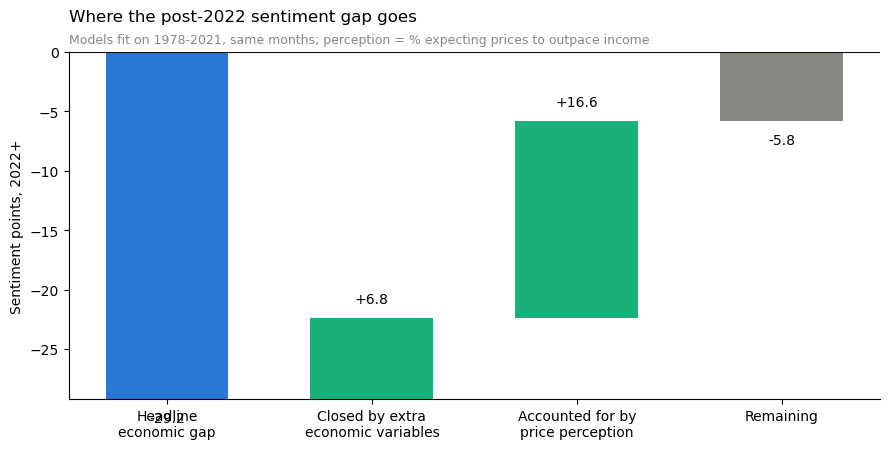

In [4]:
# Self-contained: run these cells in order in a fresh notebook. Nothing from earlier cells is needed.
# Files in the same folder: extended_monthly.csv, redbk07.xls, redbk14.xls, redbk24.xls, redbk31.xls
#
# What it does: one model that splits the post-2022 sentiment gap into
#   headline economic gap -> closed by extra economic variables -> accounted for by price perception -> remaining
# plus two placebo checks (opinions NOT about prices).

# %% Cell A -- imports and settings
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from pandas_datareader import data as web

SPLIT = '2022'
BASE = ['unemployment', 'jobs_yoy', 'inflation_yoy', 'real_wages_yoy', 'gdp_yoy']
HOUSEHOLD = ['mortgage_rates_monthly', 'food_prices_yoy', 'rent_prices_yoy', 'gas_prices_yoy',
             'house_prices_yoy', 'rdpi_yoy', 'savings', 'revolving_ratio']
PRICE_LEVEL = ['price_3yr', 'real_gas', 'groceries_vs_wage', 'goods_vs_wage']
ALL = BASE + HOUSEHOLD + PRICE_LEVEL


# %% Cell B -- your economic data + the price-level measures
d = pd.read_csv('extended_monthly.csv', index_col=0, parse_dates=True)

# prices now vs 3 years ago, chained from the 12-month inflation rates
i = d['inflation_yoy'] / 100
d['price_3yr'] = ((1 + i) * (1 + i.shift(12)) * (1 + i.shift(24)) - 1) * 100

# real gas price and prices relative to wages, from FRED
fred = web.DataReader(['APU000074714', 'CPIAUCSL', 'CUSR0000SAF11', 'CUSR0000SAC', 'AHETPI'],
                      'fred', '1975-01-01')
d['real_gas'] = fred.APU000074714 / fred.CPIAUCSL * fred.CPIAUCSL.dropna().iloc[-1]   # $/gal, today's dollars
d['groceries_vs_wage'] = fred.CUSR0000SAF11 / fred.AHETPI     # work hours per grocery basket
d['goods_vs_wage'] = fred.CUSR0000SAC / fred.AHETPI           # work hours per goods basket


# %% Cell C -- Michigan opinion questions
def read_table(path, positions, names):
    """Michigan Historical Excel: column 0 = month, 1 = year, numbers after that."""
    x = pd.read_excel(path, header=None)
    x = x[pd.to_numeric(x[1], errors='coerce').notna()]
    dates = pd.to_datetime(x[0].str.strip() + ' ' + x[1].astype(int).astype(str), format='%B %Y')
    out = x.iloc[:, positions].apply(pd.to_numeric, errors='coerce')
    out.columns = names
    out.index = dates
    return out

opinions = {
    'prices_beat_income': ('redbk14.xls', [4]),       # expect prices to rise more than income
    'w_prices': ('redbk07.xls', [6]),                 # worse off than a year ago: higher prices
    'rates_will_rise': ('redbk31.xls', [2]),          # PLACEBO: expect interest rates to go up
    'news_bad_unemployment': ('redbk24.xls', [10]),   # PLACEBO: heard bad news about unemployment
}
for col, (path, pos) in opinions.items():
    d = d.join(read_table(path, pos, [col]))

sample = d.loc['1978':, ['sentiment'] + ALL + list(opinions)].dropna()   # ONE set of months for every run
print(f'common sample: {len(sample)} months, {sample.index.min():%Y-%m} to {sample.index.max():%Y-%m}, '
      f'{(sample.index >= SPLIT).sum()} test months')


# %% Cell D -- the combined model
#   perception[t] = a_p + X[t] . g + noise
#   sentiment[t]  = a_s + X[t] . b + c * perception[t] + noise
# Shrinkage prior on all economic slopes. Fit on 1978-2021 only.
def fit_combined(perception, cols, label=''):
    s = sample
    tr = (s.index < SPLIT)
    te = ~tr
    X = s[cols]
    Z = ((X - X[tr].mean()) / X[tr].std()).values                     # training mean/sd only
    p_mean, p_sd = s[perception][tr].mean(), s[perception][tr].std()
    P = ((s[perception] - p_mean) / p_sd).values
    y = s['sentiment'].values

    with pm.Model(coords={'predictor': cols}):
        # perception equation
        a_p = pm.Normal('a_p', 0, 1)
        tau_p = pm.HalfNormal('tau_p', 1)
        g = pm.Deterministic('g', tau_p * pm.Normal('g_z', 0, 1, dims='predictor'), dims='predictor')
        s_p = pm.HalfNormal('s_p', 1)
        pm.Normal('P_obs', a_p + pm.math.dot(Z[tr], g), s_p, observed=P[tr])

        # sentiment equation
        a_s = pm.Normal('a_s', 85, 20)
        tau_s = pm.HalfNormal('tau_s', 5)
        b = pm.Deterministic('b', tau_s * pm.Normal('b_z', 0, 1, dims='predictor'), dims='predictor')
        c = pm.Normal('c', 0, 5)
        s_s = pm.HalfNormal('s_s', 10)
        pm.Normal('y_obs', a_s + pm.math.dot(Z[tr], b) + c * P[tr], s_s, observed=y[tr])

        idata = pm.sample(1000, tune=1500, chains=4, target_accept=0.95, random_seed=1)

    post = idata.posterior
    a_p_, g_ = post['a_p'].values.reshape(-1), post['g'].values.reshape(-1, len(cols))
    a_s_, b_ = post['a_s'].values.reshape(-1), post['b'].values.reshape(-1, len(cols))
    c_ = post['c'].values.reshape(-1)

    P_hat = a_p_[:, None] + g_ @ Z.T                                   # perception the economy predicts
    with_actual_P = a_s_[:, None] + b_ @ Z.T + c_[:, None] * P[None, :]
    with_usual_P = a_s_[:, None] + b_ @ Z.T + c_[:, None] * P_hat      # counterfactual

    out = {
        'gap': (y[te] - with_usual_P[:, te]).mean(axis=1),
        'through_P': (with_actual_P[:, te] - with_usual_P[:, te]).mean(axis=1),
        'remaining': (y[te] - with_actual_P[:, te]).mean(axis=1),
    }
    out['share'] = 100 * out['through_P'] / out['gap']

    def ci(x):
        return f'{x.mean():+6.1f} [{np.percentile(x, 5.5):+6.1f}, {np.percentile(x, 94.5):+6.1f}]'

    print(f'\n===== {label}: {perception}, {len(cols)} economic predictors =====')
    print(f'c (sentiment points per +1 SD)      {ci(c_)}')
    print(f'gap vs economy-only prediction      {ci(out["gap"])}')
    print(f'   accounted for by this opinion    {ci(out["through_P"])}   share {out["share"].mean():.0f}% '
          f'[{np.percentile(out["share"], 5.5):.0f}%, {np.percentile(out["share"], 94.5):.0f}%]')
    print(f'   remaining                        {ci(out["remaining"])}')
    print(f"r_hat max {float(az.summary(idata, var_names=['g', 'b', 'c'])['r_hat'].max()):.3f}   "
          f"divergences {int(idata.sample_stats.diverging.values.sum())}")
    return out


# %% Cell E -- the five runs (several minutes) and the summary
head = fit_combined('prices_beat_income', BASE, 'HEADLINE economics + price perception')
full = fit_combined('prices_beat_income', ALL, 'FULL economics + price perception')
alt = fit_combined('w_prices', ALL, 'CHECK: other price perception (upper bound)')
plac1 = fit_combined('rates_will_rise', ALL, 'PLACEBO: expect rates to rise')
plac2 = fit_combined('news_bad_unemployment', ALL, 'PLACEBO: heard bad unemployment news')

print('\n=========== SUMMARY (2022+, sentiment points) ===========')
print(f"Headline economic gap                 {head['gap'].mean():+6.1f}")
print(f"  closed by extra economic variables  {full['gap'].mean() - head['gap'].mean():+6.1f}")
print(f"  accounted for by price perception   {-full['through_P'].mean():+6.1f}")
print(f"  remaining                           {full['remaining'].mean():+6.1f}")
print('\nShare of the full-economics gap accounted for by each opinion:')
for name, r in [('price perception (main)', full), ('worse off: prices (upper bound)', alt),
                ('PLACEBO rates will rise', plac1), ('PLACEBO bad unemployment news', plac2)]:
    print(f"  {name:34s} {r['share'].mean():5.0f}%")


# %% Cell F -- waterfall figure
steps = [('Headline\neconomic gap', head['gap'].mean()),
         ('Closed by extra\neconomic variables', full['gap'].mean() - head['gap'].mean()),
         ('Accounted for by\nprice perception', -full['through_P'].mean()),
         ('Remaining', full['remaining'].mean())]
fig, ax = plt.subplots(figsize=(9, 4.6))
level = steps[0][1]
for k, (name, v) in enumerate(steps):
    if k == 0 or k == len(steps) - 1:
        bottom, color = 0, ('#2a78d6' if k == 0 else '#898781')
    else:
        bottom, color = level, '#1baf7a'
        level += v
    ax.bar(k, v, bottom=bottom, color=color, width=0.6)
    ax.text(k, bottom + v + (1 if v > 0 else -1), f'{v:+.1f}', ha='center',
            va='bottom' if v > 0 else 'top', fontsize=10)
ax.axhline(0, color='#0b0b0b', lw=0.8)
ax.set_xticks(range(len(steps)), [n for n, _ in steps])
ax.set_ylabel('Sentiment points, 2022+')
ax.set_title('Where the post-2022 sentiment gap goes', loc='left', pad=22)
ax.text(0, 1.015, 'Models fit on 1978-2021, same months; perception = % expecting prices to outpace income',
        transform=ax.transAxes, color='#898781', fontsize=9, va='bottom')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig('gap_waterfall.png', dpi=200)